# 10 - When tomorrow remembers today: time series, baselines and the broken deck

> "The vendor says their model is 90% reliable. Does it beat the rule I have used for ten years - same hour last week?" - Kestrel facilities lead

That is the facilities lead at Kestrel Operations in your first week as the team's junior
forecaster. Two claims are tangled in that one question, and both need untangling before
anyone fits anything. "90% reliable" sounds like the coverage promise Part I taught you to
build, but nobody has said 90% of what, measured how, over which hours. And "does it beat my
rule" is a question about a baseline that has had ten years to earn its place: a forecast that
simply copies the meter reading from the same hour seven days earlier.

The sharper statistical question has two halves. First: which honest simple rules must any
model beat, horizon by horizon, and how good are they on our data? Second: why does the
guarantee from notebooks 02 and 03 not transfer as-is to readings that arrive in order, where
this hour is a strong clue about the next one? This notebook answers both without fitting a
single model. That restraint is deliberate: until the simple rules have been scored, nobody
knows what a model would have to beat.

**What you will learn**

- The vocabulary of forecasting: forecast origin, horizon, period, and a band issued one time
  step at a time.
- How strongly a series remembers itself (autocorrelation), and why shuffling - the move that
  made Part I's guarantee work - destroys exactly the information we forecast with.
- The four simple rules every result must beat (persistence, two seasonal naive rules and the
  14-day median), and why each is hard to beat at some horizon.
- What the 5th-95th percentile reference band is, and why it covers well short of 90% even
  when nothing else is wrong.
- Why the misses of a time-series band arrive in bursts, and how to compare them correctly
  with what independent misses would look like.

**Where we are in the series.** Notebook 09 mapped the ways data stops being exchangeable and
showed how to test for it; time order is the violation the whole of Part II lives with, and
this is the notebook where we start living with it. Notebook 11 replaces the single holdout
used here with an honest walk-forward backtest and introduces the interval score. We lean on
notebook 02 (the split-conformal recipe and the corrected quantile), notebook 03 (the
leaderboard argument and the coverage lottery) and bonus notebook 02, which already wrapped a
forecaster with MAPIE's EnbPI on one chronological split.

## 1. From shuffled houses to ordered hours

Part I priced houses. Every listing was a row, the rows could be shuffled without losing
anything, and that shuffle was the load-bearing wall of every guarantee (notebook 03, field
guide §6). Part II forecasts meters, and a meter is the opposite of a shuffled deck: its
readings arrive in order, and the order is most of what we know about them.

Notebook 09 opened Part II with Kestrel Operations, the fictional company that runs a cloud
platform (a fleet of virtual machines) and manages a portfolio of office buildings, and used
its buildings mostly as a backdrop for the exchangeability question. From here on Kestrel's
data is the subject, so we meet its two data families properly. The operations team forecasts
two things, and both will follow us through the rest of Part II:

- **Building electricity**, hourly, per building. The forecasts feed day-ahead energy
  purchasing and peak-demand planning. The facilities lead owns these meters, and the rule.
- **VM CPU load**, every five minutes, per virtual machine. The forecasts feed capacity
  planning and autoscaling. The capacity planner owns these.

Every forecast feeds a decision, and the team also wants alarms when a meter or a VM misbehaves
(the on-call engineer's problem, notebook 14), all under a budget the head of operations signs.

The honesty note from notebook 09 bears repeating where the data first appears: all data in
Part II is simulated, inside each notebook, by generators whose docstrings say exactly what
they bake in. The real-data counterparts are public. For buildings it is the Building Data Genome 2 project (hourly meter
readings from about 1,600 non-residential buildings over 2016-2017); for the cloud it is public
VM traces such as the Azure Public Dataset (CPU utilisation in 5-minute readings). Simulation
buys us one luxury real data never offers - we know what the generator did - and the functions
below take any pandas Series with a regular timestamp index, so a real meter can replace the
simulated one.

Before any code, the vocabulary. Every Part II notebook uses these words with exactly these
meanings.

| Term | Plain English | Kestrel example | Pitfall |
|---|---|---|---|
| **forecast origin** | the moment the forecast is issued; everything it uses must already be known | 23:00 on Monday, when Tuesday's energy order is placed | using a reading that arrives after the origin, even by one step |
| **horizon** `h` | how many steps ahead of the origin the target lies | `h = 24` on the hourly meter: the same hour tomorrow | averaging accuracy over horizons: a rule can win at `h = 1` and lose at `h = 24` |
| **period** | the number of steps in one day | 24 for the hourly meter, 288 for 5-minute CPU | counting in hours when the series is not hourly |
| **persistence** (last value) | the target will look like the latest reading | next hour's load = this hour's load | it cannot see a daily cycle, so it decays fast with the horizon |
| **seasonal naive** | the target will look like the same time one cycle ago | the facilities lead's rule: same hour last week | one odd week (a holiday, a cold snap) is copied straight into the forecast |
| **prediction band** | a prediction interval issued for every future time step; drawn over time it looks like a band | a 90% band for each hour of tomorrow | reading 90% of hours covered as 90% of days covered (notebook 11) |

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the project's 90% band

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

## 2. Meet the two series

The two generators below are copied verbatim into every Part II notebook that needs them.
Read their docstrings slowly, because each bullet is a claim a later notebook tests: the
weekday rhythm is why the simple rules in section 4 are strong; the autocorrelated noise is why
misses cluster in section 6; the optional regime change breaks calibration in notebook 15; the
bursts are why simple rules are so hard to beat on cloud data (notebook 12); and the
saturation at exactly 100.0 is the innocent flat line that fools notebook 13's frozen-sensor
rule.

The protocol is fixed for all of Part II: the building runs for 730 days of hourly readings
starting 1 January 2016 (two years, like Building Data Genome 2), the VM for 30 days of
5-minute readings (like the Azure traces), both from the series seed.

In [2]:
def simulate_building_load(n_days, seed, start="2016-01-01", base_kwh=120.0,
                           occupied_kwh=180.0, hvac_kwh_per_deg=6.0, noise_frac=0.06,
                           shift_day=None, shift_frac=0.0):
    """Simulate an hourly electricity meter for one Kestrel office building.

    What the simulator bakes in (and what later notebooks test against):
    - A daily occupancy profile: busy 08:00-18:00 on weekdays, quiet nights and weekends.
      That is why 'same hour yesterday' and 'same hour last week' are strong baselines.
    - Heating and cooling: load rises when the outdoor temperature leaves a comfort zone,
      and the temperature follows the seasons, so summer and winter behave differently.
    - Noise that is autocorrelated (a busy morning tends to stay busy) and larger when the
      building is occupied. Residuals are neither independent nor equal-sized.
    - Optional regime change: from day `shift_day` on, the load level is multiplied by
      (1 + shift_frac) - a new tenant, a retrofit. Notebook 15 uses it to break calibration.

    Returns a DataFrame indexed by hourly timestamp with columns `load_kwh` and `temp_c`.
    """
    rng = np.random.default_rng(seed)
    idx = pd.date_range(start, periods=24 * n_days, freq="h")
    n = len(idx)
    hour = idx.hour.to_numpy()
    dow = idx.dayofweek.to_numpy()
    doy = idx.dayofyear.to_numpy()

    # Weather: seasons + a daily cycle + persistent anomalies (a cold week stays cold).
    anomaly = np.zeros(n)
    shocks = rng.normal(0.0, 0.6, size=n)
    for i in range(1, n):
        anomaly[i] = 0.97 * anomaly[i - 1] + shocks[i]
    temp = 12.0 - 10.0 * np.cos(2 * np.pi * (doy - 15) / 365.25) \
        + 4.0 * np.sin(2 * np.pi * (hour - 9) / 24) + anomaly

    # Occupancy: weekdays 08-18, with half-occupied shoulder hours at 07 and 18.
    occupied = ((dow < 5) & (hour >= 8) & (hour < 18)).astype(float)
    shoulder = ((dow < 5) & ((hour == 7) | (hour == 18))).astype(float) * 0.5
    occ = occupied + shoulder

    hvac = hvac_kwh_per_deg * (1.3 * np.maximum(temp - 22.0, 0.0)
                               + np.maximum(16.0 - temp, 0.0)) * (0.4 + 0.6 * occ)
    mean_load = base_kwh + occupied_kwh * occ + hvac

    # Autocorrelated, occupancy-dependent multiplicative noise.
    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.8 * ar[i - 1] + math.sqrt(1 - 0.8 ** 2) * z[i]
    load = mean_load * (1.0 + noise_frac * (1.0 + occ) * ar)

    if shift_day is not None:
        load = np.where(np.arange(n) >= 24 * shift_day, load * (1.0 + shift_frac), load)
    return pd.DataFrame({"load_kwh": np.maximum(load, 0.0), "temp_c": temp}, index=idx)


def simulate_vm_cpu(n_days, seed, start="2019-01-01", base_pct=22.0, daily_amp=8.0,
                    bursts_per_day=5.0, n_redeploys=2):
    """Simulate 5-minute average CPU utilisation (%) for one Kestrel virtual machine.

    What the simulator bakes in (and what later notebooks test against):
    - A weak daily rhythm (busier in business hours) on top of a level that jumps when the
      service is redeployed. The jumps are sudden and unannounced.
    - Bursts: spikes arriving at random times (batch jobs, traffic surges) that decay over
      a few readings. They make the series bursty - the reason simple baselines are so hard
      to beat on cloud data.
    - Readings are clipped to [0, 100]. During heavy bursts the VM saturates and reports
      exactly 100.0 several readings in a row - a legitimate flat line that a naive
      stuck-sensor rule will mistake for a frozen gateway (notebook 13).

    Returns a DataFrame indexed by 5-minute timestamp with column `cpu_pct`.
    """
    rng = np.random.default_rng(seed)
    steps_per_day = 288
    n = steps_per_day * n_days
    idx = pd.date_range(start, periods=n, freq="5min")
    hour = idx.hour.to_numpy() + idx.minute.to_numpy() / 60.0

    # Level that jumps at redeployments.
    level = np.full(n, base_pct)
    for when in np.sort(rng.integers(steps_per_day * 2, n, size=n_redeploys)):
        level[when:] = level[when:] * rng.lognormal(0.0, 0.35)

    daily = daily_amp * np.clip(np.sin(np.pi * (hour - 7) / 12), 0.0, None)

    # Bursts: random arrivals, random heights, exponential decay over a few readings.
    burst = np.zeros(n)
    n_bursts = rng.poisson(bursts_per_day * n_days)
    for start_step, height, decay in zip(rng.integers(0, n, size=n_bursts),
                                         rng.exponential(35.0, size=n_bursts),
                                         rng.uniform(2.0, 10.0, size=n_bursts)):
        span = np.arange(start_step, min(start_step + int(6 * decay), n))
        burst[span] += height * np.exp(-(span - start_step) / decay)

    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.6 * ar[i - 1] + z[i]
    cpu = level + daily + burst + 2.5 * ar
    return pd.DataFrame({"cpu_pct": np.clip(cpu, 0.0, 100.0)}, index=idx)


def run_lengths(flags):
    """Lengths of the stretches of consecutive True values in a 1-D boolean sequence.

    Used twice in this notebook: for stretches of saturated CPU readings below, and for
    streaks of consecutive band misses in section 6. Notebook 13 builds its stuck-value
    rule on the same idea.
    """
    edges = np.diff(np.concatenate([[0], np.asarray(flags, dtype=int), [0]]))
    return np.flatnonzero(edges == -1) - np.flatnonzero(edges == 1)


b = simulate_building_load(730, seed=RANDOM_SEED)   # hourly, 2016-2017, like BDG2
v = simulate_vm_cpu(30, seed=RANDOM_SEED)           # 5-minute, 30 days, like the Azure traces
y_b, y_v = b["load_kwh"], v["cpu_pct"]
PERIOD_B, PERIOD_V = 24, 288                         # steps per day

print(f"building: {len(b):,} hourly readings, {b.index[0]:%Y-%m-%d} to {b.index[-1]:%Y-%m-%d %H:%M}")
print(f"  load: mean {y_b.mean():.1f} kWh, min {y_b.min():.1f}, max {y_b.max():.1f}; "
      f"outdoor temperature {b['temp_c'].min():.1f} to {b['temp_c'].max():.1f} C")
print(f"VM: {len(v):,} five-minute readings, {v.index[0]:%Y-%m-%d} to {v.index[-1]:%Y-%m-%d %H:%M}")
print(f"  cpu: mean {y_v.mean():.1f} %, min {y_v.min():.1f}, max {y_v.max():.1f}")
saturated = (y_v == 100.0).to_numpy()
sat_runs = run_lengths(saturated)
print(f"  readings at exactly 100.0: {saturated.sum()} ({saturated.mean():.1%}), in "
      f"{len(sat_runs)} separate stretches, the longest {sat_runs.max()} readings in a row")
print("  daily median cpu, day 1 to day 30:",
      " ".join(f"{x:.0f}" for x in y_v.resample("D").median()))

building: 17,520 hourly readings, 2016-01-01 to 2017-12-30 23:00
  load: mean 199.2 kWh, min 96.5, max 493.9; outdoor temperature -8.3 to 31.3 C
VM: 8,640 five-minute readings, 2019-01-01 to 2019-01-30 23:55
  cpu: mean 49.5 %, min 13.4, max 100.0
  readings at exactly 100.0: 128 (1.5%), in 44 separate stretches, the longest 11 readings in a row
  daily median cpu, day 1 to day 30: 26 26 29 37 41 42 41 43 42 44 42 51 52 52 52 53 53 51 53 53 53 52 52 52 54 53 53 54 54 55


Two years of building, 17,520 hourly readings averaging 199.2 kWh, from a night-time floor of
96.5 kWh to a peak of 493.9 kWh, under outdoor temperatures from -8.3 to 31.3 C. The VM has
8,640 five-minute readings averaging 49.5% CPU; 128 of them (1.5%) read exactly 100.0, in 44
separate stretches of up to 11 readings in a row. That is the saturation the docstring warned
about: a VM pinned at its ceiling repeats the same number, and nothing is broken.

The row of daily medians is worth a second look, because it shows the redeploys without being
told where they are: the VM idles at 26-29% for three days, jumps on day 4 (median 37, the day
of the change) to 41-44%, and jumps again on day 12 to 51-55%. Two level jumps, both in the
first twelve days. Remember that date range; it comes back in sections 3, 4 and 5. What these
summaries do not show is any structure in time, which is where everything interesting lives.

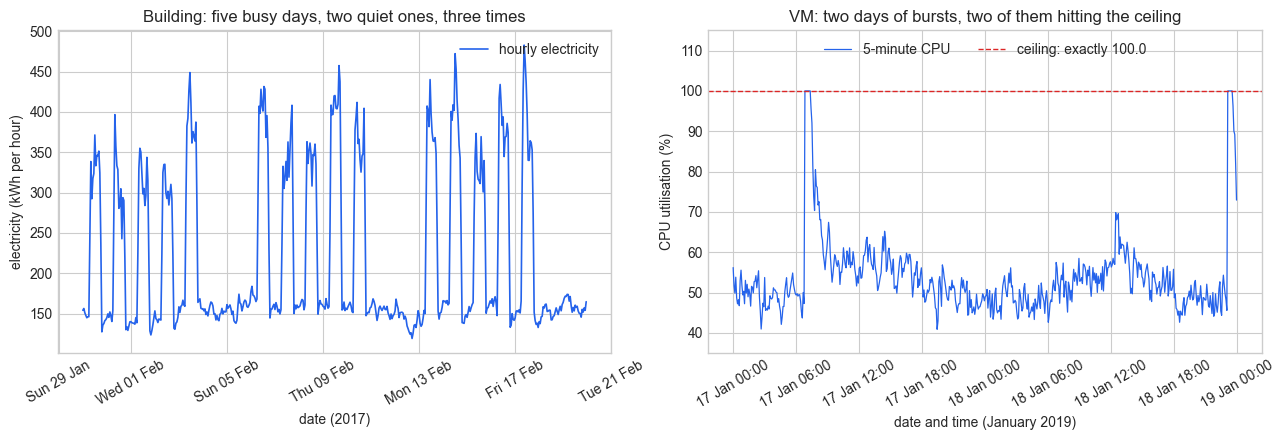

building, Tuesday 2017-02-07 10:00: 318.1 kWh at 3.6 C outside
  one hour earlier:    305.2 kWh
  same hour yesterday: 428.2 kWh (a Monday)
  same hour last week: 333.4 kWh at 8.5 C outside
VM, Thursday 2019-01-17 07:00: 100.0 %
  five minutes earlier:  100.0 %
  one hour earlier:      49.4 %
  same time yesterday:   46.2 %


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

zoom_b = y_b.loc["2017-01-30":"2017-02-19"]          # three Monday-to-Sunday weeks of winter
axes[0].plot(zoom_b.index, zoom_b, color=BLUE, linewidth=1.2, label="hourly electricity")
axes[0].set_title("Building: five busy days, two quiet ones, three times")
axes[0].set_xlabel("date (2017)")
axes[0].set_ylabel("electricity (kWh per hour)")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
axes[0].legend(loc="upper right")

zoom_v = y_v.loc["2019-01-17":"2019-01-18"]          # two days with bursts that saturate
axes[1].plot(zoom_v.index, zoom_v, color=BLUE, linewidth=0.9, label="5-minute CPU")
axes[1].axhline(100.0, color=RED, linestyle="--", linewidth=1, label="ceiling: exactly 100.0")
axes[1].set_title("VM: two days of bursts, two of them hitting the ceiling")
axes[1].set_xlabel("date and time (January 2019)")
axes[1].set_ylabel("CPU utilisation (%)")
axes[1].set_ylim(35, 115)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
axes[1].legend(loc="upper center", ncol=2)
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

# One reading of each series, read aloud next to the numbers a forecaster checks first.
t_b = pd.Timestamp("2017-02-07 10:00")
print(f"building, {t_b:%A %Y-%m-%d %H:%M}: {y_b[t_b]:.1f} kWh at {b['temp_c'][t_b]:.1f} C outside")
print(f"  one hour earlier:    {y_b[t_b - pd.Timedelta(hours=1)]:.1f} kWh")
print(f"  same hour yesterday: {y_b[t_b - pd.Timedelta(days=1)]:.1f} kWh (a Monday)")
print(f"  same hour last week: {y_b[t_b - pd.Timedelta(days=7)]:.1f} kWh "
      f"at {b['temp_c'][t_b - pd.Timedelta(days=7)]:.1f} C outside")
t_v = pd.Timestamp("2019-01-17 07:00")
print(f"VM, {t_v:%A %Y-%m-%d %H:%M}: {y_v[t_v]:.1f} %")
print(f"  five minutes earlier:  {y_v[t_v - pd.Timedelta(minutes=5)]:.1f} %")
print(f"  one hour earlier:      {y_v[t_v - pd.Timedelta(hours=1)]:.1f} %")
print(f"  same time yesterday:   {y_v[t_v - pd.Timedelta(days=1)]:.1f} %")

The left panel is the building's whole personality in three weeks: five weekday mountains,
each rising from a night floor near 150 kWh to working-hours peaks between roughly 300 and
480 kWh, then two flat weekend days that never leave the floor. The right panel is the VM's: a
level near 50% with a gentle daytime lift, interrupted by bursts that arrive without warning, decay over
minutes, and twice push the machine to the ceiling, where the line goes perfectly flat.

Here is one hour of each, read aloud:

> At 10:00 on Tuesday 7 February 2017 the meter read 318.1 kWh, with 3.6 C outside. An hour
> earlier it read 305.2 kWh. At the same hour yesterday, a Monday, it read 428.2 kWh; at the
> same hour last week, 333.4 kWh in milder weather (8.5 C). At 07:00 on Thursday 17 January 2019
> the VM read exactly 100.0%, as it had five minutes earlier; an hour before it was at 49.4%,
> and at the same time the day before at 46.2%.

Notice what you just did: you judged each reading by its neighbours in time. The hour before,
the same hour yesterday, the same hour last week - each is a candidate forecast, and for this
Tuesday two of them land within 16 kWh of the truth while the third misses by 110 kWh. Nothing
in Part I worked like this. A house's price was not a clue to the next house's price; here the
past is the main clue we have.

## 3. Tomorrow remembers today

The property we just leaned on has a name. **Autocorrelation** answers the question "how much
does the value at time t tell you about the value at time t + k?" In words: take every pair of
readings that are k steps apart, and compute the ordinary correlation between the earlier and
the later member of each pair. Near 1 means knowing now nearly tells you then; near 0 means it
tells you nothing; negative means high now goes with low then (think noon and midnight). The
number of steps k is the **lag**.

In symbols, after the words: the autocorrelation at lag $k$ is

$$\rho(k) = \frac{\operatorname{Cov}(y_t,\, y_{t+k})}{\sqrt{\operatorname{Var}(y_t)\,\operatorname{Var}(y_{t+k})}},$$

where $y_t$ is the reading at step $t$, $k$ is the lag in steps, and the covariance and the
variances are computed over every $t$ for which both readings exist. pandas computes exactly
this Pearson correlation with `Series.autocorr(lag=k)`. Plotted against $k$ it is the
**autocorrelation function** (ACF). We compute it for lags up to two weeks on the building and
up to two days on the VM.

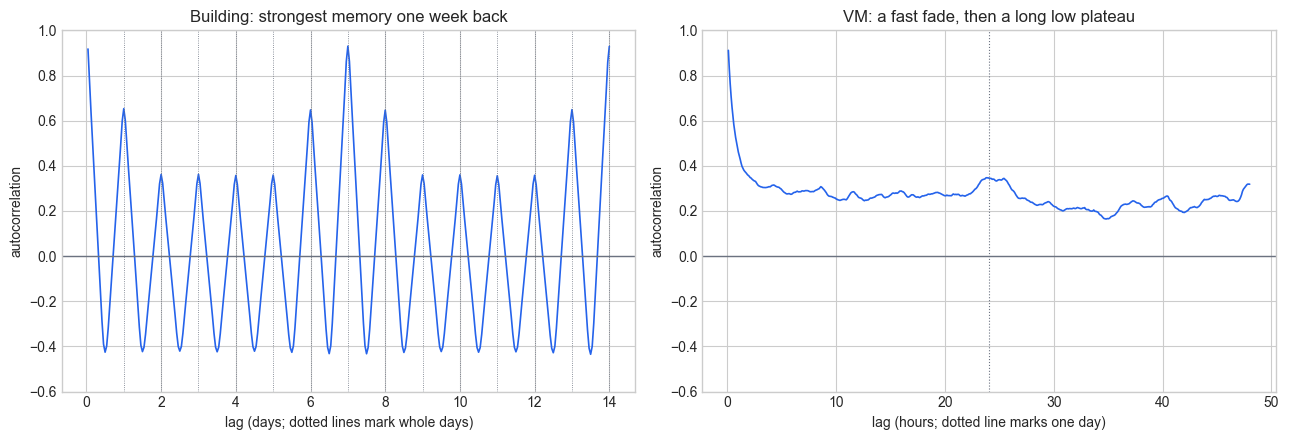

building: lag 1 h: +0.918   lag 12 h: -0.425   lag 24 h: +0.654   lag 48 h: +0.362   lag 168 h: +0.930   lag 336 h: +0.929
      VM: lag 1 x 5 min: +0.912   lag 12 x 5 min: +0.461   lag 48 x 5 min: +0.310   lag 288 x 5 min: +0.347   lag 576 x 5 min: +0.319


In [4]:
lags_b = np.arange(1, 14 * PERIOD_B + 1)     # 1 hour to 2 weeks
lags_v = np.arange(1, 2 * PERIOD_V + 1)      # 5 minutes to 2 days
acf_b = np.array([y_b.autocorr(lag=int(k)) for k in lags_b])
acf_v = np.array([y_v.autocorr(lag=int(k)) for k in lags_v])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(lags_b / PERIOD_B, acf_b, color=BLUE, linewidth=1.2)
for day in range(1, 15):
    axes[0].axvline(day, color=GRAY, linewidth=0.6, linestyle=":")
axes[0].axhline(0.0, color=GRAY, linewidth=1)
axes[0].set_title("Building: strongest memory one week back")
axes[0].set_xlabel("lag (days; dotted lines mark whole days)")
axes[0].set_ylabel("autocorrelation")
axes[1].plot(lags_v / 12, acf_v, color=BLUE, linewidth=1.2)
axes[1].axvline(24, color=GRAY, linewidth=0.8, linestyle=":")
axes[1].axhline(0.0, color=GRAY, linewidth=1)
axes[1].set_title("VM: a fast fade, then a long low plateau")
axes[1].set_xlabel("lag (hours; dotted line marks one day)")
axes[1].set_ylabel("autocorrelation")
for ax in axes:
    ax.set_ylim(-0.6, 1.0)
plt.tight_layout()
plt.show()

for name, acf, lags, unit in [("building", acf_b, (1, 12, 24, 48, 168, 336), "h"),
                              ("VM", acf_v, (1, 12, 48, 288, 576), "x 5 min")]:
    print(f"{name:>8}: " + "   ".join(f"lag {k} {unit}: {acf[k - 1]:+.3f}" for k in lags))

The building's ACF is a picket fence. One hour apart, readings correlate at +0.918; twelve
hours apart (day against night) at -0.425; one day apart at +0.654; two days apart only
+0.362, because "two days ago" pairs a working day with a weekend day on four days of the week
(Monday with Saturday, Tuesday with Sunday, Saturday with Thursday, Sunday with Friday), against
two at lag 24. Then the fence climbs
back to its highest post at exactly one week: +0.930 at lag 168, and +0.929 at two weeks. The
same hour last week is a better clue to this hour than the same hour yesterday. That one fact
is why the facilities lead's ten-year-old rule is good, and section 4 will put a number on it.

The VM forgets fast: +0.912 after 5 minutes, +0.461 after an hour, +0.310 after four hours.
Its daily rhythm is weak (+0.347 at one day), and the curve then flattens into a long plateau
near +0.3. What these numbers do not tell you is why the plateau exists, and the next cell
checks one suspect: the two redeploy jumps from section 2.

In [5]:
# Shuffle each series in time: same values, same histogram, order destroyed.
rng = np.random.default_rng(RANDOM_SEED)
shuffled_b = pd.Series(rng.permutation(y_b.to_numpy()), index=y_b.index)
shuffled_v = pd.Series(rng.permutation(y_v.to_numpy()), index=y_v.index)

# One-step persistence error: how far is each reading from the one before it?
for name, s, s_shuf in [("building", y_b, shuffled_b), ("VM", y_v, shuffled_v)]:
    print(f"{name:>8}: mean |y[t+1] - y[t]| ordered {np.mean(np.abs(np.diff(s))):6.2f}, "
          f"shuffled {np.mean(np.abs(np.diff(s_shuf))):6.2f}")
# The VM plateau: recompute the one-day autocorrelation after the second redeploy only.
after = y_v.loc["2019-01-13":]
print(f"VM one-day autocorrelation, all 30 days {y_v.autocorr(PERIOD_V):+.3f}; "
      f"days 13-30 only (no redeploy inside) {after.autocorr(PERIOD_V):+.3f}")

rows = []
for name, s, s_shuf, lags in [("building", y_b, shuffled_b, (1, 24, 168)),
                              ("VM", y_v, shuffled_v, (1, 12, 288))]:
    for k in lags:
        rows.append({"series": name, "lag (steps)": k,
                     "autocorrelation, ordered": s.autocorr(k),
                     "autocorrelation, shuffled": s_shuf.autocorr(k)})
pd.DataFrame(rows).set_index(["series", "lag (steps)"]).round(3)

building: mean |y[t+1] - y[t]| ordered  19.87, shuffled  97.33
      VM: mean |y[t+1] - y[t]| ordered   2.95, shuffled  14.28
VM one-day autocorrelation, all 30 days +0.347; days 13-30 only (no redeploy inside) +0.149


autocorrelation, ordered  autocorrelation, shuffled
series   lag (steps)                                                     
building 1                               0.918                      0.002
         24                              0.654                     -0.006
         168                             0.930                      0.014
VM       1                               0.912                     -0.006
         12                              0.461                     -0.020
         288                             0.347                      0.003

Shuffling keeps every value and destroys every clue. The building's one-hour autocorrelation
drops from 0.918 to 0.002 and its one-week autocorrelation from 0.930 to 0.014; the VM's drops
from 0.912 to -0.006 at 5 minutes. The persistence error says the same thing in kWh: in the
real order a reading sits on average 19.87 kWh from the one before it, after shuffling 97.33
kWh, almost five times further. On the VM the gap is 2.95 against 14.28 points of CPU. The
plateau suspect is confirmed too: restricted to days 13-30, with no redeploy inside, the VM's one-day
autocorrelation falls from +0.347 to +0.149. Most of the plateau was readings sharing a level
because they sat on the same side of a jump.

**Why this breaks Part I, in plain words.** Notebook 09 showed that exchangeability means
"shuffling changes nothing" and mapped the ways real data violates it; time order is the
violation this whole Part lives with, and the table above shows why it is not a small one. In
Part I a shuffle was harmless - it destroyed nothing the model used - and it was precisely what
the guarantee needed. Here a shuffle destroys the very information we forecast with. There is
a crisp way to see that ordered data cannot be exchangeable: if any rearrangement leaves the
joint distribution unchanged, then every pair of positions looks alike, so the correlation
between two readings cannot depend on how far apart they are. An ACF that reads +0.918 at one
lag and -0.425 at another is a signed confession that position matters.

**What time-series methods assume instead.** Conformal methods for time series swap
exchangeability for weaker, time-aware assumptions. The two you will meet in papers are
**stationary** - the rules that generate the series do not change over time, so a Tuesday in
March is generated the same way as a Tuesday in May - and **mixing** - the past matters, but
its influence fades, so readings far apart are nearly independent. EnbPI (Xu and Xie 2021, the
method bonus notebook 02 ran through MAPIE) and SPCI (Xu and Xie 2023) lean on these to get
approximate, large-sample coverage. Be honest about our data: the building is not stationary in
the strict sense (the seasons move its level) and the VM's level jumps at redeploys. ACI and
conformal PID (notebook 15) need even less: their long-run guarantee holds for any sequence at
all, at the price of saying nothing about any particular week.

One trap this autocorrelation sets for later. scikit-learn's histogram gradient boosting turns
on automatic early stopping by default for more than 10,000 rows, and it does so by holding out
a random 10% of the rows to decide when to stop. On a series with lag-one autocorrelation 0.918,
every randomly held-out hour sits between two training neighbours that nearly give it away, so
the stopping rule is graded on near-copies of its own training data. That is why the shared
Part II model, `quantile_gbm`, sets `early_stopping=False` (notebook 11 puts it among the ways a
backtest lies).

## 4. Four rules to beat

Every forecasting result must be measured against simple rules, because simple rules are
astonishingly hard to beat: they have no parameters, so they cannot overfit and cannot leak;
they use the most recent information available; and they encode exactly the structure that
dominates the series. Forecasting competitions have shown this repeatedly - the M-competitions
organised by Makridakis and colleagues are the classic record of sophisticated methods struggling
to beat simple benchmarks. Four rules, each in words first. Here $t$ is the forecast origin,
$h$ the horizon, $P$ the period (steps per day), $y_t$ the reading at $t$, and $\hat y_{t+h}$ the
forecast for the target $t + h$.

- Persistence: whatever the meter says now, it will say at the target. $\hat y_{t+h} = y_t$.
- Seasonal naive, daily: the target will look like the same time yesterday.
  $\hat y_{t+h} = y_{t+h-P}$.
- Seasonal naive, weekly (the facilities lead's rule): the target will look like the same
  time last week. $\hat y_{t+h} = y_{t+h-7P}$.
- **14-day median**: the target will look like a typical day at this time of day, judged over
  the last two weeks. $\hat y_{t+h} = \operatorname{median}\{\, y_{t+h-kP} : k = 1, \dots, 14 \,\}$.

The three seasonal rules look back from the target, not from the origin, so they need
$h \le P$: the same time yesterday must already have happened when the forecast is issued.
They also do not depend on the horizon at all - for a given target they return the same number
whether you ask an hour or a day ahead. Only persistence ages with $h$.

| Rule | What it assumes | Why it is hard to beat | Where it breaks |
|---|---|---|---|
| persistence | the near future looks like now | absorbs the current level, any recent shock and any level jump instantly | cannot see the daily cycle: from 23:00 it predicts the 10:00 peak at night-time level |
| same time yesterday | each day repeats the previous one | captures the daily cycle at this week's level | weekday-weekend switches: Monday is forecast from Sunday, Saturday from Friday |
| same time last week | each week repeats the previous one | captures the daily and the weekly cycle, the building's strongest memory (+0.930) | copies last week's oddities: a holiday, a cold snap, a redeploy since |
| 14-day median | this time of day is usually like this | robust: one burst or one odd day cannot move a median | mixes weekdays and weekends 10 to 4, and lags a level change by about a week |

The shared function below turns a series into a supervised table, one row per forecast origin,
with the four rules (and the percentile band of section 5) as columns computed under the same
no-peeking rule as any model feature would be. It is copied verbatim; read its docstring.

In [6]:
def make_direct_table(y, h, period, exog=None):
    """Turn a series into a supervised table for forecasting h steps ahead.

    One row per forecast origin t. Every feature uses only values known at time t
    (y[t], y[t-1], ...); the target is y[t + h]. `period` is the number of steps per day
    (24 for hourly meters, 288 for 5-minute CPU). Requires h <= period, so that 'same time
    yesterday' (relative to the target) is already observed at the origin.

    The four simple baselines and the past-percentile reference band are columns of this
    table, computed with exactly the same no-peeking rule as the model features.
    """
    assert h <= period, "h must not exceed one day, or 'same time yesterday' is in the future"
    v = y.to_numpy(dtype=float)
    n = len(v)
    target_pos = np.arange(n) + h

    def at(offset):
        """Value at position (t + offset) for every origin t; NaN when out of range."""
        pos = np.arange(n) + offset
        out = np.full(n, np.nan)
        ok = (pos >= 0) & (pos < n)
        out[ok] = v[pos[ok]]
        return out

    same_time_past_days = np.column_stack([at(h - k * period) for k in range(1, 15)])
    table = pd.DataFrame({
        "last_value": v,
        "mean_last_day": pd.Series(v).rolling(period).mean().to_numpy(),
        "same_time_yesterday": same_time_past_days[:, 0],
        "same_time_last_week": same_time_past_days[:, 6],
        "median_14d_same_time": np.median(same_time_past_days, axis=1),
        "p05_14d_same_time": np.percentile(same_time_past_days, 5, axis=1),
        "p95_14d_same_time": np.percentile(same_time_past_days, 95, axis=1),
    }, index=y.index)
    target_time = y.index + h * (y.index[1] - y.index[0])
    table["target_hour"] = target_time.hour + target_time.minute / 60.0
    table["target_dow"] = target_time.dayofweek
    if exog is not None:
        # Treated as a forecast known in advance (e.g. tomorrow's weather forecast).
        e = exog.to_numpy(dtype=float)
        exog_at_target = np.full(n, np.nan)
        ok = target_pos < n
        exog_at_target[ok] = e[target_pos[ok]]
        table["exog_at_target"] = exog_at_target
    table["target"] = at(h)
    table["target_time"] = target_time
    return table.dropna().copy()


BASELINES = ["last_value", "same_time_yesterday", "same_time_last_week", "median_14d_same_time"]

HORIZONS = {"building": (1, 24), "VM": (1, 12, 48)}   # next hour, day ahead | 5 min, 1 h, 4 h
SERIES = {"building": (y_b, PERIOD_B), "VM": (y_v, PERIOD_V)}
tables = {(fam, h): make_direct_table(SERIES[fam][0], h, SERIES[fam][1])
          for fam in HORIZONS for h in HORIZONS[fam]}
for (fam, h), tab in tables.items():
    print(f"{fam:>8}, h = {h:>2}: {len(tab):,} rows, targets from "
          f"{tab['target_time'].iloc[0]:%Y-%m-%d %H:%M} to {tab['target_time'].iloc[-1]:%Y-%m-%d %H:%M}")

# At h = 24 the reading 24 hours before the target IS the reading at the origin.
t24 = tables[("building", 24)]
assert np.array_equal(t24["last_value"], t24["same_time_yesterday"]), \
    "at h = period, persistence and same-time-yesterday must be the same forecast"
print("building, h = 24: last_value equals same_time_yesterday on every row (asserted)")

# One row, read in full: the origin 10:00 on Monday 6 February 2017, target 24 hours later.
t24.loc[[pd.Timestamp("2017-02-06 10:00")],
        ["last_value", "same_time_yesterday", "same_time_last_week", "median_14d_same_time",
         "p05_14d_same_time", "p95_14d_same_time", "target", "target_time"]].round(1)

building, h =  1: 17,184 rows, targets from 2016-01-15 00:00 to 2017-12-30 23:00
building, h = 24: 17,184 rows, targets from 2016-01-15 00:00 to 2017-12-30 23:00
      VM, h =  1: 4,608 rows, targets from 2019-01-15 00:00 to 2019-01-30 23:55
      VM, h = 12: 4,608 rows, targets from 2019-01-15 00:00 to 2019-01-30 23:55
      VM, h = 48: 4,608 rows, targets from 2019-01-15 00:00 to 2019-01-30 23:55
building, h = 24: last_value equals same_time_yesterday on every row (asserted)


,last_value,same_time_yesterday,same_time_last_week,median_14d_same_time,p05_14d_same_time,p95_14d_same_time,target,target_time
2017-02-06 10:00:00,428.2,428.2,333.4,327.3,143.2,433.3,318.1,2017-02-07 10:00:00


The last line looks up a single row: the origin 10:00 on Monday 6 February 2017, forecasting
10:00 on Tuesday, the hour we read aloud in section 2. Its target is 318.1 kWh; the weekly rule
says 333.4, persistence and same-time-yesterday both say 428.2, and the 14-day median says
327.3 (the two percentile columns are section 5's band). The assertion above it is an
identity worth knowing before it surprises you: at `h = 24` the hour 24 hours before the target
is the origin itself, so "last value" and "same hour yesterday" are the same forecast on every
one of the 17,184 rows. That is not a bug, and it is why the two columns
will show identical errors below.

The row counts deserve a sentence too. The 14-day features need 14 days of history before the
first row exists, so every table starts with targets on day 15: 17,184 rows of the building's
17,520 hours, and 4,608 rows of the VM's 8,640 readings. On a 30-day VM trace, the warm-up
consumes almost half the data. Real cloud traces are often this short; plan for it.

We now score each rule on the second half of each series - a single chronological holdout, the
simplest honest choice. It is not yet the protocol a project report needs (one holdout is one
draw; notebook 11 builds the walk-forward backtest), but it is enough to rank the rules.

In [7]:
HOLDOUT_START = {"building": y_b.index[len(y_b) // 2], "VM": y_v.index[len(y_v) // 2]}

rows = []
for (fam, h), tab in tables.items():
    hold = tab[tab["target_time"] >= HOLDOUT_START[fam]]
    row = {"family": fam, "h": h, "holdout rows": len(hold)}
    for rule in BASELINES:
        row[rule] = np.mean(np.abs(hold["target"] - hold[rule]))   # MAE of each rule
    best = min(BASELINES, key=lambda r: row[r])
    row["best rule"] = best
    row["best MAE as % of mean"] = 100 * row[best] / hold["target"].mean()
    rows.append(row)
mae_table = pd.DataFrame(rows).set_index(["family", "h"])

print(f"holdout: building targets from {HOLDOUT_START['building']:%Y-%m-%d}, "
      f"VM targets from {HOLDOUT_START['VM']:%Y-%m-%d}")
print("MAE in kWh (building) and in percentage points of CPU (VM); lower is better")
mae_table.round(3)

holdout: building targets from 2016-12-31, VM targets from 2019-01-16
MAE in kWh (building) and in percentage points of CPU (VM); lower is better


holdout rows  last_value  same_time_yesterday  same_time_last_week  median_14d_same_time             best rule  \
family   h                                                                                                                    
building 1           8760      19.824               43.351               22.599                40.063            last_value   
         24          8760      43.351               43.351               22.599                40.063   same_time_last_week   
VM       1           4320       2.800                7.796                9.248                 6.578            last_value   
         12          4320       7.649                7.796                9.248                 6.578  median_14d_same_time   
         48          4320       9.224                7.796                9.248                 6.578  median_14d_same_time   

             best MAE as % of mean  
family   h                          
building 1                   9.959  
         24                 11.353  
VM       1                   5.091  
         12                 11.957  
         48                 11.957

Read the table one family at a time, one horizon at a time - never averaged.

**Building.** For the next hour, persistence wins: MAE 19.824 kWh, ahead of the weekly rule
at 22.599. For the day ahead, persistence collapses to 43.351 (it is now the same forecast as
same-hour-yesterday, as asserted) and the facilities lead's rule wins comfortably at 22.599
kWh, 11.4% of the mean load. The 14-day median is poor at both horizons (40.063): it mixes ten
weekdays with four weekend days, so every weekend daytime hour is forecast at weekday level.

**VM.** At 5 minutes, persistence is unbeatable among the rules (2.800 points of CPU). At one
hour its error nearly triples (7.649) and the 14-day median takes over (6.578); at four hours
persistence has decayed to 9.224 and the median, which does not care about the horizon, still
sits at 6.578. On a bursty machine the typical value at this time of day is a better guess
than a reading taken an hour ago, because the reading an hour ago may have been a burst.

What the table does not say: it does not say these rules are good. A best MAE of 11.4% of mean
load is the bar a model must clear, not a result to celebrate. And with one holdout per family,
small gaps (19.8 against 22.6) are suggestive rather than settled. The next picture shows what
the rules are actually doing.

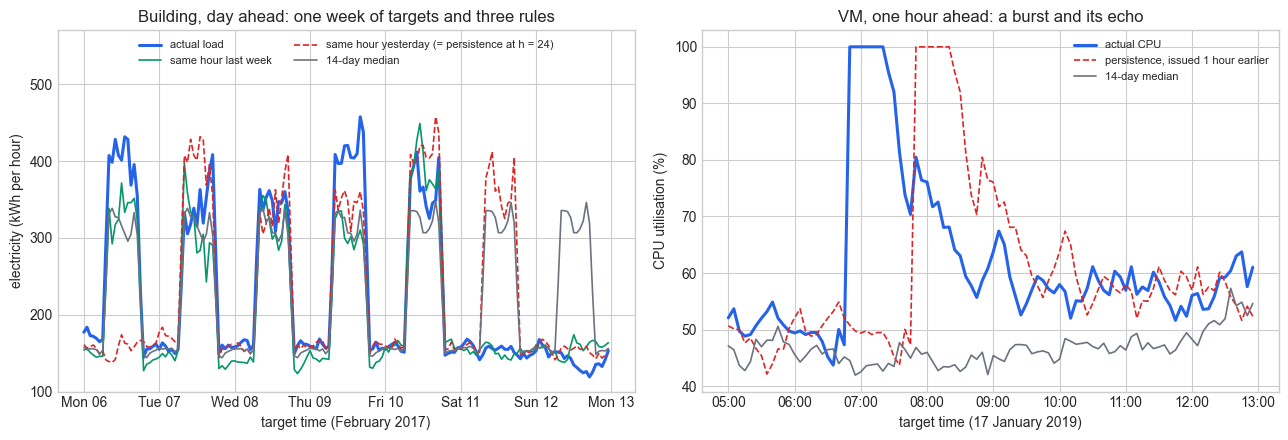

VM readings at 100.0 between 06:50 and 07:20; persistence forecasts 100.0 for targets 07:50 to 08:20


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

week = t24[(t24["target_time"] >= "2017-02-06") & (t24["target_time"] < "2017-02-13")]
axes[0].plot(week["target_time"], week["target"], color=BLUE, linewidth=2.2, label="actual load")
axes[0].plot(week["target_time"], week["same_time_last_week"], color=GREEN, linewidth=1.2,
             label="same hour last week")
axes[0].plot(week["target_time"], week["same_time_yesterday"], color=RED, linewidth=1.2,
             linestyle="--", label="same hour yesterday (= persistence at h = 24)")
axes[0].plot(week["target_time"], week["median_14d_same_time"], color=GRAY, linewidth=1.2,
             label="14-day median")
axes[0].set_title("Building, day ahead: one week of targets and three rules")
axes[0].set_xlabel("target time (February 2017)")
axes[0].set_ylabel("electricity (kWh per hour)")
axes[0].set_ylim(100, 570)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
axes[0].legend(loc="upper center", ncol=2, fontsize=8)

t12 = tables[("VM", 12)]
burst = t12[(t12["target_time"] >= "2019-01-17 05:00") & (t12["target_time"] < "2019-01-17 13:00")]
axes[1].plot(burst["target_time"], burst["target"], color=BLUE, linewidth=2.2, label="actual CPU")
axes[1].plot(burst["target_time"], burst["last_value"], color=RED, linewidth=1.2, linestyle="--",
             label="persistence, issued 1 hour earlier")
axes[1].plot(burst["target_time"], burst["median_14d_same_time"], color=GRAY, linewidth=1.2,
             label="14-day median")
axes[1].set_title("VM, one hour ahead: a burst and its echo")
axes[1].set_xlabel("target time (17 January 2019)")
axes[1].set_ylabel("CPU utilisation (%)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

sat_target = burst.loc[burst["target"] == 100.0, "target_time"]
sat_echo = burst.loc[burst["last_value"] == 100.0, "target_time"]
print(f"VM readings at 100.0 between {sat_target.min():%H:%M} and {sat_target.max():%H:%M}; "
      f"persistence forecasts 100.0 for targets {sat_echo.min():%H:%M} to {sat_echo.max():%H:%M}")

The left panel is the building's story in one week. The green weekly rule tracks the blue truth
through all seven days, weekday mountains and weekend plains alike. The red dashed rule copies
yesterday, so it is right on Tuesday to Friday and badly wrong twice a week: it predicts a
working Monday from a quiet Sunday and a quiet Saturday from a working Friday. The gray median
is wrong in a different way: it sits at weekday level through both weekend days' daytime
hours, because ten of its fourteen values are weekdays.

The right panel is the VM's story in eight hours. The burst saturates the machine from 06:50 to
07:20; persistence, issued an hour earlier, forecasts 100.0 for targets from 07:50 to 08:20 -
the burst's echo, arriving exactly when the burst has gone. The median ignores the burst
entirely and sits below the truth all morning: its 14 days reach back past the day-12
redeploy, so it remembers a lower level. Each rule has a failure you can point at, and the best rule per
horizon is the one whose failure costs least on that horizon.

That is the rule for the rest of Part II, and for your project: a model must beat the *best*
simple rule, per family and per horizon, not the worst one and not an average (field guide
§17). A vendor deck that beats same-hour-yesterday at the day-ahead horizon has beaten 43.4 kWh
and lost to 22.6. "The model did not beat the rule" is a valid, reportable result.

## 5. The reference band: percentiles of the past

The point forecast answers "what number?"; the facilities lead also needs "how sure?". The
simplest band anyone builds reuses the 14-day median's ingredients. In words: take the same 14
past readings at this time of day, and use their 5th percentile as the lower edge and their
95th percentile as the upper edge. Ninety percent of the past fell between those two numbers,
so - the reasoning goes - ninety percent of the future will too. This is the **percentile
band**, and in this project it is the reference band every conformal band will be compared
with: it is what a careful engineer builds without any of Part I.

In symbols: the band for target $t + h$ is $[\,Q_{0.05},\ Q_{0.95}\,]$ of the set
$\{ y_{t+h-kP} : k = 1, \dots, 14 \}$, where $Q_p$ is numpy's linear-interpolation percentile and
the other symbols are as in section 4. Like the seasonal rules it depends only on the target
time, never on the horizon. The 14-day median is its centre.

In [9]:
rows = []
for fam in ("building", "VM"):
    tab = tables[(fam, 1)]
    hold = tab[tab["target_time"] >= HOLDOUT_START[fam]]
    lo, hi, y = hold["p05_14d_same_time"], hold["p95_14d_same_time"], hold["target"]
    rows.append({"family": fam, "holdout rows": len(hold),
                 "coverage": np.mean((y >= lo) & (y <= hi)),
                 "share below the band": np.mean(y < lo),
                 "share above the band": np.mean(y > hi),
                 "mean width": np.mean(hi - lo),
                 "width as % of mean": 100 * np.mean(hi - lo) / y.mean()})
band_table = pd.DataFrame(rows).set_index("family")

# The band ignores the horizon: same target time, same band, at h = 1 and h = 24.
a = tables[("building", 1)].set_index("target_time")
c = tables[("building", 24)].set_index("target_time")
common = a.index.intersection(c.index)
assert np.allclose(a.loc[common, "p05_14d_same_time"], c.loc[common, "p05_14d_same_time"])
print(f"building band identical at h = 1 and h = 24 on {len(common):,} shared targets (asserted)")
band_table.round(3)

building band identical at h = 1 and h = 24 on 17,184 shared targets (asserted)


,holdout rows,coverage,share below the band,share above the band,mean width,width as % of mean
family,,,,,,
building,8760,0.800,0.097,0.103,128.317,64.462
VM,4320,0.847,0.026,0.127,26.294,47.799


The reference band promises 90% by construction and delivers 0.800 on the building and 0.847
on the VM. It is also wide: 128.3 kWh on average on the building, 64% of the mean load, and 26.3
points of CPU on the VM. The two families miss in different ways. The building's misses are
balanced (9.7% below, 10.3% above). The VM's are lopsided: 12.7% above the band, only 2.6%
below. What the table does not tell you is why a band built from "90% of the past" covers 80%
of the future. Three reasons, each of which can be measured; the first is pure arithmetic.

14 past readings at 10:00 before 2017-02-07: min 141.7, 5th percentile 143.2, 95th percentile 433.3, max 442.8 kWh
AssertionError: calibration window too short for this alpha (field guide S1)


exchangeable             normal: 5th-95th band covers 0.798, full range [min, max] covers 0.867 (theory 13/15 = 0.867)
exchangeable skewed (lognormal): 5th-95th band covers 0.796, full range [min, max] covers 0.867 (theory 13/15 = 0.867)
building: below all 14 past readings 0.061, above all 14 0.066 (flat would be 0.067 each)
      VM: below all 14 past readings 0.018, above all 14 0.085 (flat would be 0.067 each)


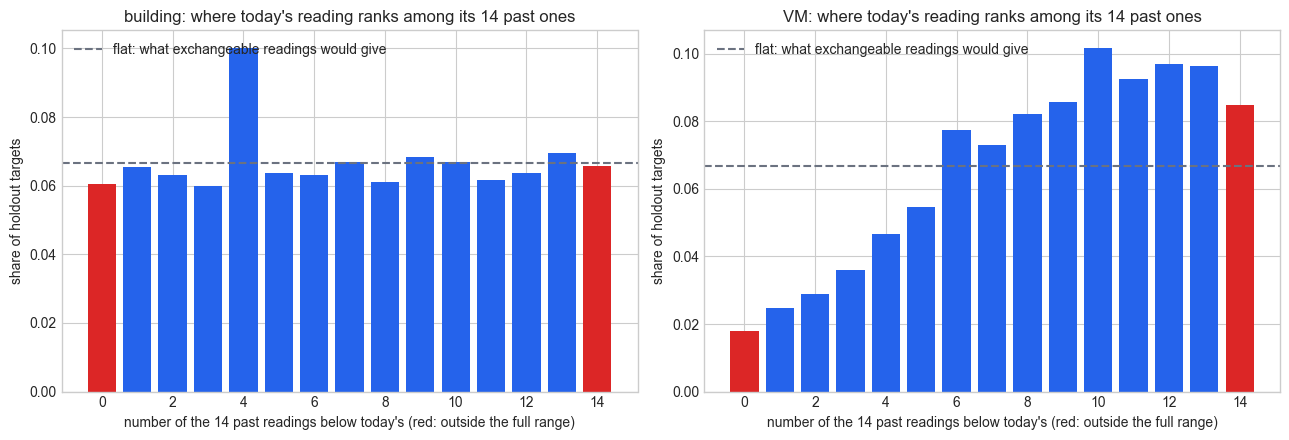

In [10]:
# Reason 1, committed: ask notebook 02's corrected quantile for an honest 95% upper edge
# from the 14 past same-hour readings of the hour we read aloud in section 2.
def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02: the k-th smallest score, k = ceil((n+1)(1-alpha))."""
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    assert k <= n, "calibration window too short for this alpha (field guide S1)"
    return float(np.sort(scores)[k - 1])


past14 = np.array([y_b[t_b - pd.Timedelta(days=k)] for k in range(1, 15)])
print(f"14 past readings at 10:00 before {t_b:%Y-%m-%d}: min {past14.min():.1f}, "
      f"5th percentile {np.percentile(past14, 5):.1f}, 95th percentile "
      f"{np.percentile(past14, 95):.1f}, max {past14.max():.1f} kWh")
try:
    corrected_quantile(past14, 0.05)          # the upper edge of an equal-tailed 90% band
except AssertionError as err:
    print(f"AssertionError: {err}")

# The same band under perfect conditions: 15 exchangeable values, 14 past and 1 new.
rng = np.random.default_rng(RANDOM_SEED)
for shape, draws in [("normal", rng.normal(size=(100_000, 15))),
                     ("skewed (lognormal)", rng.lognormal(0.0, 1.0, size=(100_000, 15)))]:
    past, new = draws[:, :14], draws[:, 14]
    in_band = (new >= np.percentile(past, 5, axis=1)) & (new <= np.percentile(past, 95, axis=1))
    in_range = (new >= past.min(axis=1)) & (new <= past.max(axis=1))
    print(f"exchangeable {shape:>18}: 5th-95th band covers {in_band.mean():.3f}, "
          f"full range [min, max] covers {in_range.mean():.3f} (theory 13/15 = {13 / 15:.3f})")

# Rank of each holdout target among its own 14 past same-time readings (notebook 03's leaderboard).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, fam in zip(axes, ("building", "VM")):
    y, period = SERIES[fam]
    tab = tables[(fam, 1)]
    hold = tab[tab["target_time"] >= HOLDOUT_START[fam]]
    pos = y.index.get_indexer(hold["target_time"])
    past = np.column_stack([y.to_numpy()[pos - k * period] for k in range(1, 15)])
    rank = (past < y.to_numpy()[pos][:, None]).sum(axis=1)       # 0 = below all 14
    share = np.bincount(rank, minlength=15) / len(rank)
    ax.bar(np.arange(15), share, color=np.where((np.arange(15) == 0) | (np.arange(15) == 14),
                                                RED, BLUE))
    ax.axhline(1 / 15, color=GRAY, linestyle="--", linewidth=1.5,
               label="flat: what exchangeable readings would give")
    ax.set_title(f"{fam}: where today's reading ranks among its 14 past ones")
    ax.set_xlabel("number of the 14 past readings below today's (red: outside the full range)")
    ax.set_ylabel("share of holdout targets")
    ax.legend(loc="upper left")
    print(f"{fam:>8}: below all 14 past readings {share[0]:.3f}, above all 14 {share[14]:.3f} "
          f"(flat would be {1 / 15:.3f} each)")
plt.tight_layout()
plt.show()

The first printout is the arithmetic, committed. The fourteen past readings ran from 141.7 to
442.8 kWh, and numpy's 5th and 95th percentiles (143.2 and 433.3) sit inside that range. Asking
notebook 02's corrected quantile for an honest 95% upper edge fires its assertion: the rank it
needs is $\lceil 15 \times 0.95 \rceil = 15$ of 14 values, which does not exist (field guide §1).

The plain-English reason is notebook 03's leaderboard. If today's reading and the 14 past ones
were exchangeable, today's would be equally likely to take any of the 15 rank positions. It
falls outside the full range only in the two extreme positions, so even $[\min, \max]$ covers
just 13 of 15. In symbols: with $n$ exchangeable past values, the chance that a new value lands
between their minimum and maximum is $(n - 1)/(n + 1)$, which is 0.867 for $n = 14$ and reaches
0.90 only at $n = 19$. The simulation agrees to the third decimal (0.867 for both shapes), and
it prices the 5th-95th band under perfect conditions at 0.798 (normal) or 0.796 (skewed). So
the building's 0.800 is almost exactly what perfectly exchangeable readings would give - partly
by luck, as the next cell shows: weekday over-coverage and weekend under-coverage cancel. Either
way, the band was never going to deliver 90%, with or without time order.

The rank plots say which family respects the leaderboard. The building's ranks are close to
flat: today's reading lands below all 14 past ones 6.1% of the time and above all 14 6.6% of
the time, against 6.7% for each under exchangeability. Its one bump, at 4, is where the two
regimes meet: a weekend hour usually ranks somewhere from 0 to 4 (below every weekday value in
its fortnight), a weekday working hour from 4 to 14 (above every weekend value). The VM's ranks
lean hard to the right: only 1.8% below all 14, 8.5% above. That tilt is the VM's level
problem: for most of the holdout, the 14 past days reach back before the day-12 redeploy, so
the past sits lower than the present. The band, which ignores the current level, misses upward.

In [11]:
tab = tables[("building", 1)]
hold_b = tab[tab["target_time"] >= HOLDOUT_START["building"]].copy()
lo, hi, y = hold_b["p05_14d_same_time"], hold_b["p95_14d_same_time"], hold_b["target"]
hold_b["covered"] = (y >= lo) & (y <= hi)
hold_b["below"] = y < lo
hold_b["above"] = y > hi
hold_b["width"] = hi - lo
weekday = hold_b["target_dow"] < 5
office = (hold_b["target_hour"] >= 8) & (hold_b["target_hour"] < 18)
hold_b["slice"] = np.where(~weekday, "weekend, all hours",
                           np.where(office, "weekday, 08-18", "weekday, other hours"))
hold_b["month"] = hold_b["target_time"].dt.month

by_month = hold_b.groupby("month")[["covered", "below", "above"]].mean()
print("building band by month of the holdout (share covered / below / above):")
print(by_month.round(3).T.to_string())

agg = {"covered": "mean", "below": "mean", "above": "mean", "width": "mean"}
by_slice = hold_b.groupby("slice").agg(agg).rename(columns={
    "covered": "coverage", "below": "share below", "above": "share above",
    "width": "mean width (kWh)"})
by_slice["rows"] = hold_b.groupby("slice").size()
by_slice.round(3)

building band by month of the holdout (share covered / below / above):
month       1      2      3      4      5      6      7      8      9      10     11     12
covered  0.790  0.771  0.817  0.815  0.769  0.839  0.804  0.827  0.794  0.790  0.758  0.828
below    0.103  0.110  0.110  0.154  0.117  0.076  0.090  0.103  0.100  0.063  0.075  0.063
above    0.106  0.119  0.073  0.031  0.114  0.085  0.106  0.070  0.106  0.147  0.167  0.109


,coverage,share below,share above,mean width (kWh),rows
slice,,,,,
"weekday, 08-18",0.858,0.000,0.142,250.094,2600
"weekday, other hours",0.808,0.088,0.104,41.308,3640
"weekend, all hours",0.731,0.210,0.059,128.354,2520


Reasons two and three are in these two tables.

**It mixes weekdays and weekends.** For a weekday working hour the 14 past values are ten
working hours and four weekend hours, so the lower edge drops to weekend level: the band is
250.1 kWh wide, covers 0.858, and never misses below (0.000) - it misses above (0.142), when
today's working hour beats the highest weekday values. For a weekend hour the same mix runs the
other way: the band's middle and upper part is made of weekday values, today's quiet reading
falls below the band 21.0% of the time, and coverage drops to 0.731. The overall 0.800 is an
average of a wide band that over-serves weekdays and a misplaced one that fails weekends.

**It ignores the current level.** The month row shows the seasons pushing the band around.
In November, as heating load climbs week by week, 16.7% of readings land above a band built
from the milder fortnight before; in April, as heating fades, 15.4% land below it. The VM's
upward tilt in the rank plot is the same failure with a redeploy instead of a season.

| Reason | What happens | Measured here | Who fixes it |
|---|---|---|---|
| 14 values are a tiny sample | 5th and 95th percentiles of 14 values sit inside their range; no finite-sample correction (field guide §1) | 0.796-0.798 under perfect exchangeability; building 0.800 | the corrected quantile over a larger calibration set (notebooks 11-12) |
| it mixes weekdays and weekends | one band for two regimes: too wide on weekdays, misplaced on weekends | weekday 08-18: 0.858 at 250.1 kWh wide; weekend: 0.731 | models with calendar features, CQR bands (notebook 12) |
| it ignores the current level | the past fortnight lags a season or a redeploy | November 16.7% above, April 15.4% below; VM 12.7% above | features that see the recent level; online recalibration (notebook 15) |

This band stays in the project as the reference: notebooks 11 and 12 report it next to every
conformal band, with its measured coverage, never as a 90% band.

## 6. The deck is not shuffled: misses arrive in bursts

Now we commit the mistake a Part I graduate would make on day one. Take the facilities lead's
rule as the point forecast, and wrap it in notebook 02's recipe exactly: absolute residual as
the score, corrected quantile, band = forecast plus or minus `q_hat`. Calibrate on four
contiguous weeks of day-ahead forecasts, then evaluate on the following eight weeks. Nothing
here is wrong with the recipe; what is wrong is the assumption underneath it, that the hours of
the test weeks are shuffled from the same deck as the calibration hours.

We calibrate on the four weeks starting Monday 24 April 2017 and test on the eight weeks after
(22 May to 16 July), with one detail a Part I graduate would miss. The first test forecast, for
00:00 on Monday 22 May, is issued at its origin 24 hours earlier, 00:00 on Sunday 21 May. At
that moment Sunday's remaining 23 hours have not happened, so they cannot be calibration
targets: we drop them. That is the h-step purge, which notebook 11 defines properly and makes
mandatory for every backtest. This window was chosen because its overall coverage comes out close to
the target, so the overall number cannot be blamed for what follows; the last cell of this
section repeats the experiment on every window of both series.

In [12]:
tab = tables[("building", 24)]          # day-ahead origins: the facilities lead's use case
CAL_START = pd.Timestamp("2017-04-24")  # a Monday
TEST_START = CAL_START + pd.Timedelta(weeks=4)
TEST_END = TEST_START + pd.Timedelta(weeks=8)
cal = tab[(tab["target_time"] >= CAL_START) & (tab["target_time"] < TEST_START)]
test = tab[(tab["target_time"] >= TEST_START) & (tab["target_time"] < TEST_END)]

# The purge: the first test forecast is issued at its origin, h = 24 hours before its target.
# Every calibration target must already have happened by then, so later ones are dropped.
first_origin = test.index[0]
n_purged = int((cal["target_time"] > first_origin).sum())
q_leaky = corrected_quantile(np.abs(cal["target"] - cal["same_time_last_week"]).to_numpy(), ALPHA)
cal = cal[cal["target_time"] <= first_origin]
assert cal["target_time"].max() <= first_origin, "a calibration target lies after the first test origin"

# Notebook 02's recipe around the weekly rule: score, corrected quantile, symmetric band.
scores = np.abs(cal["target"] - cal["same_time_last_week"]).to_numpy()
q_hat = corrected_quantile(scores, ALPHA)
resid = (test["target"] - test["same_time_last_week"]).to_numpy()
miss = np.abs(resid) > q_hat              # True = the truth fell outside the band

n_test = len(miss)
coverage = 1 - miss.mean()
se_binomial = math.sqrt(coverage * (1 - coverage) / n_test)
print(f"first test origin {first_origin:%Y-%m-%d %H:%M}; the purge drops the {n_purged} calibration "
      f"targets after it (without the purge, q_hat would be {q_leaky:.1f} kWh)")
print(f"calibration: {len(cal)} hours ({cal['target_time'].iloc[0]:%Y-%m-%d %H:%M} to "
      f"{cal['target_time'].iloc[-1]:%Y-%m-%d %H:%M}); q_hat = {q_hat:.1f} kWh, band width {2 * q_hat:.1f} kWh")
print(f"test: {n_test} hours ({TEST_START:%Y-%m-%d} to {TEST_END - pd.Timedelta(hours=1):%Y-%m-%d})")
print(f"coverage {coverage:.3f} ({miss.sum()} misses); binomial standard error "
      f"{se_binomial:.3f}, so 'within noise' would be roughly {coverage - 2 * se_binomial:.3f} "
      f"to {coverage + 2 * se_binomial:.3f}")

first test origin 2017-05-21 00:00; the purge drops the 23 calibration targets after it (without the purge, q_hat would be 50.5 kWh)
calibration: 649 hours (2017-04-24 00:00 to 2017-05-21 00:00); q_hat = 51.2 kWh, band width 102.5 kWh
test: 1344 hours (2017-05-22 to 2017-07-16)
coverage 0.906 (127 misses); binomial standard error 0.008, so 'within noise' would be roughly 0.890 to 0.921


By every Part I yardstick this band is fine. After the purge, 649 calibration hours give
`q_hat` = 51.2 kWh (50.5 without the purge: a small leak here, but the habit is what matters), a
band 102.5 kWh wide, and over 1,344 test hours it covers 0.906, with 127 misses - right on the
budget of one miss in ten. The binomial standard error from notebook 02 (0.008) says anything
between about 0.890 and 0.921 is consistent with the promise. A Part I report would stop here
and write "90% coverage confirmed". What the number does not say is how the 127 misses are
arranged in time, and that is the question a meter forces on you.

To answer it we need a reference: what would the same misses look like if they did not travel
together? Getting that reference right is most of the work, and there are three candidates.

- **Coin flips at `ALPHA`**: every hour misses independently with probability 0.10. The
  textbook picture, but it lets the number of misses wobble.
- **A plain shuffle**: the same 127 misses, dealt into random hours. This is the exact
  exchangeable reference - same count, same length, no position special.
- **A calendar-preserving shuffle**: the same misses, shuffled only among hours that share an
  hour of day and a day type (weekday or weekend). Independent does not have to mean equally
  likely at every hour. The docstring warned that the noise is larger when the building is
  occupied, so a constant-width band should miss more at 11:00 than at 03:00 even if every
  miss were independent. This shuffle keeps each hour's own miss rate and destroys only the
  order within the day. It is the fair reference, and the hardest one to beat.

In [13]:
def longest_runs(flags):
    """Longest run of consecutive True values in each row of a 2-D boolean array.

    Vectorised over rows, so 10,000 reference sequences cost one pass over the steps.
    """
    flags = np.atleast_2d(flags)
    current = np.zeros(flags.shape[0], dtype=int)
    best = np.zeros(flags.shape[0], dtype=int)
    for column in flags.T:
        current = np.where(column, current + 1, 0)
        best = np.maximum(best, current)
    return best


def miss_statistics(flags, steps_per_day):
    """Clustering statistics for hit/miss sequences, one sequence per row (True = miss).

    Every statistic except the miss rate grows when misses travel together. A sequence
    must cover whole days starting at midnight, so daily coverage is per calendar day.
    """
    flags = np.atleast_2d(flags)
    n_rows, n = flags.shape
    n_streaks = flags[:, 0].astype(int) + (flags[:, 1:] & ~flags[:, :-1]).sum(axis=1)
    daily = 1 - flags.reshape(n_rows, n // steps_per_day, steps_per_day).mean(axis=2)
    return {
        "miss rate": flags.mean(axis=1),
        "mean streak length (steps)": flags.sum(axis=1) / n_streaks,
        "longest streak (steps)": longest_runs(flags),
        "P(miss | previous step missed)": (flags[:, 1:] & flags[:, :-1]).sum(axis=1)
                                          / flags[:, :-1].sum(axis=1),
        "SD of daily coverage": daily.std(axis=1),
        "days with coverage below 0.75": (daily < 0.75).sum(axis=1),
    }


def calendar_shuffle(flags, stratum, rng, n_ref):
    """Shuffle values only among steps that share a calendar stratum.

    `stratum` labels each step (here: hour of day x weekday/weekend). Each stratum keeps
    its own values - its own miss count, or its own errors - so misses may still
    concentrate in busy hours; what the shuffle destroys is the order in time.
    Works for hit/miss flags and for error sizes. Returns n_ref shuffled sequences.
    """
    flags = np.asarray(flags)
    out = np.empty((n_ref, len(flags)), dtype=flags.dtype)
    for label in np.unique(stratum):
        idx = np.flatnonzero(stratum == label)
        out[:, idx] = rng.permuted(np.tile(flags[idx], (n_ref, 1)), axis=1)
    return out


R = 10_000
rng = np.random.default_rng(RANDOM_SEED)
stratum = (test["target_hour"].astype(int) * 2 + (test["target_dow"] >= 5)).to_numpy()
references = {
    "coin flips at ALPHA": rng.random((R, n_test)) < ALPHA,
    "shuffle": rng.permuted(np.tile(miss, (R, 1)), axis=1),
    "calendar shuffle": calendar_shuffle(miss, stratum, rng, R),
}
observed = miss_statistics(miss, 24)
columns = {"observed": {k: float(val[0]) for k, val in observed.items()}}
for name, ref in references.items():
    stats = miss_statistics(ref, 24)
    columns[f"{name}: median"] = {k: np.median(val) for k, val in stats.items()}
    if name != "coin flips at ALPHA":
        columns[f"{name}: 99th pct"] = {k: np.percentile(val, 99) for k, val in stats.items()}
comparison = pd.DataFrame(columns)

working = ((test["target_dow"] < 5) & (test["target_hour"] >= 8) & (test["target_hour"] < 18)).to_numpy()
print(f"weekday 08-18 hours: {working.mean():.1%} of test hours, {miss[working].sum() / miss.sum():.1%} "
      f"of misses; miss rate inside them {miss[working].mean():.3f}, outside {miss[~working].mean():.3f}")
streak_counts = np.bincount(run_lengths(miss))
print("observed streaks by length: " + ", ".join(f"{n} of {k} h" for k, n in enumerate(streak_counts) if n))
longest = int(observed["longest streak (steps)"][0])
cal_ref = miss_statistics(references["calendar shuffle"], 24)
print(f"calendar shuffles with a streak of {longest} hours or more: "
      f"{(cal_ref['longest streak (steps)'] >= longest).sum()} of {R:,} "
      f"(longest in any of them: {cal_ref['longest streak (steps)'].max()} hours); "
      f"with P(miss | previous missed) >= {observed['P(miss | previous step missed)'][0]:.3f}: "
      f"{(cal_ref['P(miss | previous step missed)'] >= observed['P(miss | previous step missed)'][0]).sum()}")
# Memory of the error size, with and without the calendar: busy hours sit next to busy
# hours, so part of any raw autocorrelation is reason one again, not memory.
def lag1_autocorr(rows):
    return np.array([np.corrcoef(r[:-1], r[1:])[0, 1] for r in np.atleast_2d(rows)])

abs_err = np.abs(resid)
scaled_err = abs_err / pd.Series(abs_err).groupby(stratum).transform("median").to_numpy()
for label, err in [("raw |error|", abs_err), ("|error| divided by its stratum's median", scaled_err)]:
    ref_ac = lag1_autocorr(calendar_shuffle(err, stratum, rng, 2_000))
    print(f"lag-1 autocorrelation, {label}: {lag1_autocorr(err)[0]:.3f} "
          f"(calendar shuffle: median {np.median(ref_ac):.3f}, 99th pct {np.percentile(ref_ac, 99):.3f})")

# Standard error of the overall coverage. Weekends are always fully covered here, a fixed
# calendar effect, so the day-to-day spread is measured within each day type (stratified).
daily_cov = 1 - miss.reshape(-1, 24).mean(axis=1)
weekend_day = test["target_dow"].to_numpy().reshape(-1, 24)[:, 0] >= 5
se_days = math.sqrt(sum(m.mean() ** 2 * daily_cov[m].var(ddof=1) / m.sum()
                        for m in (weekend_day, ~weekend_day)))
rates = pd.Series(miss).groupby(stratum).agg(["mean", "size"])
se_own_rates = math.sqrt((rates["size"] * rates["mean"] * (1 - rates["mean"])).sum()) / n_test
print(f"standard error of coverage: from day-to-day spread within day types {se_days:.3f}; "
      f"if every hour missed independently at its own stratum's rate {se_own_rates:.3f}; "
      f"binomial formula {se_binomial:.3f}")
comparison.round(3)

weekday 08-18 hours: 29.8% of test hours, 94.5% of misses; miss rate inside them 0.300, outside 0.007
observed streaks by length: 33 of 1 h, 8 of 2 h, 14 of 3 h, 2 of 4 h, 1 of 5 h, 2 of 6 h, 1 of 11 h
calendar shuffles with a streak of 11 hours or more: 0 of 10,000 (longest in any of them: 10 hours); with P(miss | previous missed) >= 0.520: 0
lag-1 autocorrelation, raw |error|: 0.659 (calendar shuffle: median 0.338, 99th pct 0.397)


lag-1 autocorrelation, |error| divided by its stratum's median: 0.534 (calendar shuffle: median -0.003, 99th pct 0.059)
standard error of coverage: from day-to-day spread within day types 0.012; if every hour missed independently at its own stratum's rate 0.007; binomial formula 0.008


,observed,coin flips at ALPHA: median,shuffle: median,shuffle: 99th pct,calendar shuffle: median,calendar shuffle: 99th pct
miss rate,0.094,0.100,0.094,0.094,0.094,0.094
mean streak length (steps),2.082,1.110,1.104,1.187,1.396,1.549
longest streak (steps),11.000,3.000,3.000,4.000,4.000,7.000
P(miss | previous step missed),0.520,0.099,0.094,0.157,0.283,0.354
SD of daily coverage,0.108,0.060,0.059,0.072,0.079,0.089
days with coverage below 0.75,4.000,0.000,0.000,2.000,1.000,3.000


The misses travel together, for two separate reasons, and the three references pull them apart.

**Reason one: the misses live in the busy hours.** Weekday working hours are 29.8% of the test
hours and hold 94.5% of the misses: inside them the band misses at a rate of 0.300, outside at
0.007. One constant width for every hour is too generous at night and too tight at noon, the
same complaint the Hearthstone desk made about villas in notebook 05. That alone makes misses
neighbours: under the plain shuffle a miss is followed by another with probability 0.094
(the miss rate, as independence demands), while under the calendar-preserving shuffle, which
keeps misses in the busy hours, it is already 0.283.

**Reason two: within the busy hours, misses chain.** The observed chance of a miss right after
a miss is 0.520, far above even the calendar shuffle's 99th percentile (0.354). Of the 61
separate streaks, 33 are single hours, but 20 last three hours or longer. The longest
streak was 11 consecutive hours outside the band - a whole working day and more - where the
calendar shuffle has a median of 4 and a 99th percentile of 7, and not one of its 10,000
sequences reached 11 (its longest was 10). Streaks average 2.08 hours against 1.40 for the
calendar shuffle. The coin flips at `ALPHA` tell the same story as the plain shuffle, so the
conclusion does not depend on which naive reference you prefer.

The mechanism behind reason two is the memory of section 3, but measuring it needs the same
care as the references. The size of the weekly rule's error - the absolute gap between this
hour and the same hour last week - has lag-one autocorrelation 0.659, and part of that raw
number is reason one again: busy hours sit next to busy hours. Shuffling the errors within
their calendar strata, which removes all memory and keeps the calendar, still leaves 0.338
(99th percentile 0.397). Divide each error by the median error of its own hour of day and day
type, and the autocorrelation is 0.534, against -0.003 (99th percentile 0.059) for the same
shuffle. Roughly half of the raw 0.659 was the calendar; the rest is memory: when this Tuesday
is colder or busier than last Tuesday at 10:00, it is usually also colder or busier at 11:00.

Clustered misses also carry less information than independent ones. Weekends are always fully
covered in this window - a fixed calendar effect, not noise - so we measure the day-to-day
spread within each day type. It gives a standard error of 0.012 for the overall 0.906, against
0.007 if every hour missed independently at its own stratum's rate. That is about one and a
half times the binomial 0.008 the previous cell used, so its "within noise" range was too
narrow by about a third.

A plain-English rule shows why streaks are so rare under independence. If misses were
independent, a miss would carry no news about the next hour, so a streak that has started
survives each extra hour only with probability equal to the miss rate. In symbols: with miss
rate $p$, the chance that a streak, once started, lasts at least $k$ steps is $p^{\,k-1}$. At
the overall rate $p \approx 0.1$ an 11-hour streak happens once in $10^{10}$ streaks; even at
the working-hours rate $p \approx 0.3$ it is about 6 in a million.

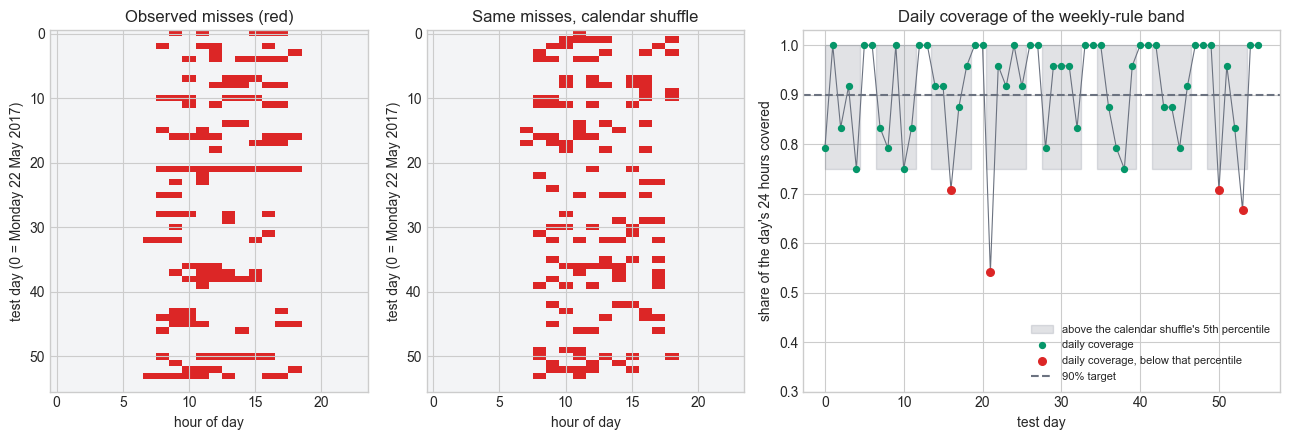

fully covered days: 22 of 56, of which 16 weekend days (of 16); weekdays with at least one miss: 34 of 40
daily coverage: worst day 0.542 (13 of 24 hours); days below 0.75: 4; red days (below the calendar shuffle's 5th percentile for that day): 4 of 56, coverage 0.708, 0.542, 0.708, 0.667
expected number of red days if the misses had no memory: 2.8 or fewer
weekly coverage: 0.899 0.887 0.911 0.905 0.929 0.911 0.923 0.881


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.5]})
grid_cmap = plt.matplotlib.colors.ListedColormap(["#F3F4F6", RED])
calendar_example = references["calendar shuffle"][0]
for ax, flags, title in [(axes[0], miss, "Observed misses (red)"),
                         (axes[1], calendar_example, "Same misses, calendar shuffle")]:
    ax.imshow(flags.reshape(-1, 24), aspect="auto", cmap=grid_cmap, interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("hour of day")
    ax.set_ylabel("test day (0 = Monday 22 May 2017)")

days = np.arange(len(daily_cov))
calendar_daily = 1 - references["calendar shuffle"].reshape(R, -1, 24).mean(axis=2)
p5_days = np.percentile(calendar_daily, 5, axis=0)       # per test day: weekdays and weekends differ
below = daily_cov < p5_days
axes[2].fill_between(days, p5_days, 1.0, step="mid", color=GRAY, alpha=0.2,
                     label="above the calendar shuffle's 5th percentile")
axes[2].plot(days, daily_cov, color=GRAY, linewidth=0.8)
axes[2].scatter(days[~below], daily_cov[~below], color=GREEN, s=18, zorder=3,
                label="daily coverage")
axes[2].scatter(days[below], daily_cov[below], color=RED, s=30, zorder=3,
                label="daily coverage, below that percentile")
axes[2].axhline(1 - ALPHA, color=GRAY, linestyle="--", linewidth=1.5, label="90% target")
axes[2].set_ylim(0.3, 1.03)
axes[2].set_title("Daily coverage of the weekly-rule band")
axes[2].set_xlabel("test day")
axes[2].set_ylabel("share of the day's 24 hours covered")
axes[2].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

print(f"fully covered days: {np.sum(daily_cov == 1.0)} of {len(daily_cov)}, of which "
      f"{np.sum(daily_cov[weekend_day] == 1.0)} weekend days (of {weekend_day.sum()}); weekdays with at "
      f"least one miss: {np.sum(daily_cov[~weekend_day] < 1.0)} of {(~weekend_day).sum()}")
print(f"daily coverage: worst day {daily_cov.min():.3f} ({int(round(daily_cov.min() * 24))} of 24 hours); "
      f"days below 0.75: {np.sum(daily_cov < 0.75)}; red days (below the calendar shuffle's 5th "
      f"percentile for that day): {below.sum()} of {len(daily_cov)}, coverage "
      + ", ".join(f"{c:.3f}" for c in daily_cov[below]))
print(f"expected number of red days if the misses had no memory: {0.05 * len(daily_cov):.1f} or fewer")
weekly_cov = 1 - miss.reshape(-1, 24 * 7).mean(axis=1)
print("weekly coverage:", " ".join(f"{w:.3f}" for w in weekly_cov))

The two grids hold exactly the same red cells, and both keep them in the working hours - that
is reason one, visible as the empty columns at night. The difference is the shape. In the real
order the misses form long horizontal bars, runs of consecutive hours on the same day; shuffled
within the calendar, the same misses break into short dashes spread over more days. The daily
panel shows what the bars cost. Only 22 of the 56 days are fully covered, and 16 of those are
the weekends: 34 of the 40 weekdays have at least one miss. The worst day covered 0.542 (13 of
24 hours inside), and 4 days fell below 75%, where the calendar shuffle's median is 1 and its
99th percentile 3. Daily coverage has a standard deviation of 0.108, above the calendar
shuffle's 99th percentile of 0.089. The 4 red dots are those same four
days, each below the 5th percentile the calendar shuffle produces for that particular day -
where chance alone would put at most about 2.8. So the streaks do not multiply the number of
unusual days much; they pile misses into the same days, and the bad days get worse.

The weekly row cuts the other way, and it is just as important: weekly coverage runs from
0.881 to 0.929, which is unremarkable. In this window the streaks last hours, not days, so they
wash out over a week. Bad weeks need something slower - a season turning, a new tenant - and
that is notebook 15's subject, not this one.

**Why this cannot happen under exchangeability.** Vovk, Gammerman and Shafer (2005) proved the
sharpest version: in the online setting, where the conformal predictor recalibrates after every
new observation and breaks ties at random, the hit/miss sequence on exchangeable data is
exactly a sequence of independent coin flips, each a miss with probability alpha. Our band,
with one fixed calibration window, has a milder version: given the calibration window, the
misses on independent, identically distributed hours would be independent flips at that
window's own rate (notebook 03's lottery ticket). Either way a miss would carry no news about
the next hour, and no hour of the day would be special. Here both fail. That makes the plain
shuffle a permutation test of exchangeability in the sense of field guide §14, and the
calendar-preserving shuffle a sharper test of something more specific: whether the hours remember
each other even after the calendar has been accounted for. They do.

The consequences shape the rest of Part II. Reason one is predictable and therefore fixable: a
band whose width depends on the hour (CQR with calendar features, notebook 12) stops spending
its misses in the busy hours. Reason two is not fixable by any calendar feature, and it changes
how bands must be evaluated and used: daily coverage swings far more than hourly coverage
suggests, so a promise about hours is not a promise about days (notebook 11 measures joint
coverage); a band edge used as an alarm limit fires in storms, not at a steady trickle (notebook
14); and when the cause of the misses is slower than a few hours, "90% on average" can hide a
terrible week (notebook 15). Before generalising from one window and one family, the last cell
repeats the experiment everywhere.

In [15]:
def window_experiment(tab, point_col, cal_start, cal_len, test_len, steps_per_day, rng, n_ref=2_000):
    """Split conformal around a simple rule on one window, against a calendar shuffle.

    Calibrate on targets in [cal_start, cal_start + cal_len), test on the test_len after.
    Calibration targets after the first test origin are purged. Returns the observed
    clustering statistics, the calendar shuffle's 99th percentiles of the longest streak
    and of P(miss | previous step missed), and the shuffle's median of the latter.
    """
    test_start = cal_start + cal_len
    cal = tab[(tab["target_time"] >= cal_start) & (tab["target_time"] < test_start)]
    test = tab[(tab["target_time"] >= test_start) & (tab["target_time"] < test_start + test_len)]
    cal = cal[cal["target_time"] <= test.index[0]]     # the purge, as in the cell above
    q = corrected_quantile(np.abs(cal["target"] - cal[point_col]).to_numpy(), ALPHA)
    flags = (np.abs(test["target"] - test[point_col]) > q).to_numpy()
    strat = (test["target_hour"].astype(int) * 2 + (test["target_dow"] >= 5)).to_numpy()
    out = {k: float(val[0]) for k, val in miss_statistics(flags, steps_per_day).items()}
    ref = miss_statistics(calendar_shuffle(flags, strat, rng, n_ref), steps_per_day)
    out["ref 99th pct: longest streak"] = float(np.percentile(ref["longest streak (steps)"], 99))
    out["ref 99th pct: P(miss | previous)"] = float(
        np.percentile(ref["P(miss | previous step missed)"], 99))
    out["ref median: P(miss | previous)"] = float(np.median(ref["P(miss | previous step missed)"]))
    return out


rng = np.random.default_rng(RANDOM_SEED)
designs = [
    # name, table, point forecast, calibration, test, first start, step, steps per day
    ("building, day ahead, same hour last week", tables[("building", 24)], "same_time_last_week",
     pd.Timedelta(weeks=4), pd.Timedelta(weeks=8), pd.Timestamp("2016-01-18"), pd.Timedelta(weeks=4), 24),
    ("VM, 5 min ahead, persistence", tables[("VM", 1)], "last_value",
     pd.Timedelta(days=2), pd.Timedelta(days=4), pd.Timestamp("2019-01-15"), pd.Timedelta(days=2), 288),
]
summary = {}
for name, tab_w, point_col, cal_len, test_len, start, step, spd in designs:
    one_step = tab_w["target_time"].iloc[1] - tab_w["target_time"].iloc[0]
    results = []
    while start + cal_len + test_len <= tab_w["target_time"].iloc[-1] + one_step:
        results.append(window_experiment(tab_w, point_col, start, cal_len, test_len, spd, rng))
        start += step
    res = pd.DataFrame(results)
    coverage_w = 1 - res["miss rate"]
    print(f"{name}: per-window calendar-shuffle medians of P(miss | previous missed) "
          f"{res['ref median: P(miss | previous)'].min():.3f} to {res['ref median: P(miss | previous)'].max():.3f}"
          + (f"; observed " + ", ".join(f"{x:.3f}" for x in res["P(miss | previous step missed)"])
             if len(res) <= 10 else ""))
    summary[name] = {
        "windows": len(res),
        "coverage: median": coverage_w.median(),
        "coverage: lowest": coverage_w.min(),
        "coverage: highest": coverage_w.max(),
        "mean streak length (steps): median": res["mean streak length (steps)"].median(),
        "P(miss | previous missed): median": res["P(miss | previous step missed)"].median(),
        "P(miss | previous missed): reference median": res["ref median: P(miss | previous)"].median(),
        "P(miss | previous missed): reference 99th pct": res["ref 99th pct: P(miss | previous)"].median(),
        "P(miss | previous missed): windows above reference": int((res["P(miss | previous step missed)"]
                                   > res["ref 99th pct: P(miss | previous)"]).sum()),
        "longest streak (steps): median": res["longest streak (steps)"].median(),
        "longest streak (steps): reference 99th pct": res["ref 99th pct: longest streak"].median(),
        "longest streak (steps): windows above reference": int((res["longest streak (steps)"]
                                    > res["ref 99th pct: longest streak"]).sum()),
    }
pd.DataFrame(summary).round(3)

building, day ahead, same hour last week: per-window calendar-shuffle medians of P(miss | previous missed) 0.130 to 0.447


VM, 5 min ahead, persistence: per-window calendar-shuffle medians of P(miss | previous missed) 0.094 to 0.167; observed 0.160, 0.238, 0.219, 0.148, 0.160, 0.204


,"building, day ahead, same hour last week","VM, 5 min ahead, persistence"
windows,23.000,6.000
coverage: median,0.900,0.895
coverage: lowest,0.839,0.870
coverage: highest,0.955,0.917
mean streak length (steps): median,2.243,1.223
P(miss | previous missed): median,0.554,0.182
P(miss | previous missed): reference median,0.279,0.128
P(miss | previous missed): reference 99th pct,0.353,0.195
P(miss | previous missed): windows above reference,23.000,3.000
longest streak (steps): median,8.000,4.000


The chosen window was typical, not special. Across 23 building windows (calibration starting
every four weeks from January 2016, each followed by eight test weeks, so test periods overlap),
each window is compared with its own calendar shuffle (calibration purged as above). The
reference rows give, across windows, the median of each window's own shuffle median and of its
own 99th percentile. The chance of a miss right after a miss has a median of 0.554, against a
typical shuffle value of 0.279, and is above its own window's 99th percentile in 23 of 23
windows. Streaks average 2.2 hours (median over windows), and the longest streak (median 8
hours) beats its window's 99th percentile in 16 of 23. Overall coverage itself runs from 0.839
to 0.955 around a median of 0.900. That spread is wider than notebook 03's lottery predicts for 649 calibration hours
(roughly 0.88 to 0.92), for two reasons this notebook has now shown: the calibration weeks and
the test weeks sit in different parts of the season, and clustered misses make every eight-week
estimate noisier than the binomial formula admits.

The VM's misses chain too, but in short pairs. Across 6 windows (two days of calibration, four
of test, 5-minute persistence), coverage runs from 0.870 to 0.917, and a miss is followed by
another with median probability 0.182, against a typical calendar-shuffle value of 0.128 (the
per-window shuffle medians run from 0.094 to 0.167). In 3 of the 6 windows the observed value
is above its own window's 99th percentile, where chance would put about 0.06 windows, so the
chaining is real. What the VM lacks is long streaks: streaks average 1.22 readings, and the
longest (median 4) beats its window's 99th percentile in only 1 of 6. The burst of section 4 is
the likely mechanism: the jump up and the first steep step of its decay are two large
persistence errors in a row, after which the changes shrink back inside the band.

Clustering is a property of the residual's memory, and P(miss | previous miss) against a
calendar shuffle is the way to measure it: about twice the reference on the building (0.554
against 0.279), with streaks of hours, and about one and a half times the reference on the VM
(0.182 against 0.128), with pairs of readings. With four test days per window, the VM figures
are worth re-checking on a longer real trace.

## 7. Common mistakes to avoid

1. **Beating the wrong baseline.** A model that beats same hour yesterday on the building's
   day-ahead horizon has beaten 43.4 kWh, the worst rule there, while same hour last week sits
   at 22.6. Score all four rules per family and per horizon, and beat the best one; "the model
   did not win" is a reportable result (field guide §17).
2. **Averaging the horizons.** The best rule changes with the horizon: persistence wins the
   building's next hour (19.8 against 22.6 kWh) and loses its day ahead (43.4 against 22.6); on
   the VM, persistence wins at 5 minutes and the 14-day median at 1 and 4 hours. One averaged
   MAE would hide both flips (field guide §17; for bands, §19).
3. **Calling the percentile band a 90% band.** It covered 0.800 on the building and 0.847 on
   the VM, and 14 past values cannot carry an honest equal-tailed 90% band at all: the
   corrected quantile's assertion fires (field guide §1). Quote it as the reference it is, with
   its measured coverage.
4. **Shuffling a time series, or letting a library shuffle it for you.** A random split or a
   random early-stopping holdout puts near-copies of every test hour into training (lag-one
   autocorrelation 0.918). Split by time, refit per block and calibrate on earlier data
   (field guide §6 and §15, notebook 11).
5. **Reading overall coverage as the whole story.** The weekly-rule band covered 0.906 over
   eight weeks and still produced an 11-hour miss streak and four days below 75%. Report daily
   coverage and miss streaks next to the overall number, compare them with a shuffle that
   keeps the calendar (a plain shuffle or coin flips at alpha set the bar too low), and do not
   quote the binomial standard error for clustered misses: here the day-to-day spread gave
   0.012, against 0.007 for independent misses at each hour's own rate (field guide §14 and
   §19).
6. **Forgetting the warm-up.** The 14-day features consume the first 14 days of every series:
   the VM's 30 days leave 16 days of usable rows, and the second-half holdout takes 15 of them.
   State how many rows your evaluation really has.
7. **Calibrating on targets the forecaster had not seen yet.** At `h = 24`, a calibration
   window that ends where the test begins contains 23 hours that have not happened when the
   first test forecast is issued. Purge them (field guide §15, notebook 11); here the purge
   moved `q_hat` from 50.5 to 51.2 kWh, but the habit is what makes a backtest honest.

## 8. What to say in the project report

**Strong version**

> "We benchmarked four simple forecasting rules on a simulated office-building meter (hourly,
> two years) and a simulated VM CPU trace (5-minute, 30 days), scoring each on the second half
> of its series separately per horizon. The best rule depends on the horizon: for the building,
> persistence one hour ahead (MAE 19.8 kWh) and the facilities team's same-hour-last-week rule
> one day ahead (22.6 kWh, 11.4% of mean load); for the VM, persistence at 5 minutes (2.8
> points of CPU) and the 14-day median at 1 and 4 hours (6.6). A proposed model must beat the
> best rule at each horizon. The 14-day 5th-95th percentile reference band covers 80.0% on the
> building and 84.7% on the VM, not 90%; with 14 past values no honest two-sided 90% band
> exists. A split-conformal band around the weekly rule covered 90.6% of 1,344 test hours, but
> its misses cluster in two ways. They concentrate in weekday working hours (94.5% of misses in
> 29.8% of the hours), and within those hours they chain: after a miss the next hour missed 52%
> of the time, against 28% when the same misses are shuffled within each hour of day and day
> type, and the 11-hour longest streak was never reached in 10,000 such shuffles. On the VM,
> 5-minute persistence misses chain only in short pairs (18% against 12.8%). We therefore
> evaluate with walk-forward backtests and report daily coverage and miss streaks alongside
> hourly coverage."

**Weak version**

> "The vendor's model is 90% reliable, our percentile band is also a 90% band, and the
> conformal band hit 90.6%, so the coverage guarantee holds for our meters."

The weak version accepts "90% reliable" without asking 90% of what, at which horizon, against
which rule; it calls a band that covered 80% a 90% band; and it quotes an exchangeable-data
guarantee for hours whose misses arrive in 11-hour streaks. The strong version names the rule
to beat at every horizon, quotes the reference band at its measured coverage, and reports the
clustering that the overall number hides.

### The one-line summary

Ordered data changes both questions this notebook started with. "Is the model good?" becomes
"does it beat the best simple rule at this horizon?" - and the rule to beat moves from
persistence to the weekly rule to the 14-day median as the horizon and the family change.
"Is the band calibrated?" becomes "is it calibrated, and how do its misses arrive?" - because
an hour that misses makes the next hour likely to miss too, and the Part I guarantee was built
for a deck in which that could never happen.

In a time series, the question is not whether you miss, but whether your misses travel together.